# Parte prática – CRISP-DM aplicado ao MVC Finance

**Disciplina:** Ciência de Dados e Aprendizagem de Máquina – A1 · **Docente:** Profa. Kadidja Valéria
**Projeto-base:** TCC *MVC Finance: aplicativo web de gestão financeira pessoal* (UDF, 2026)

Este notebook executa as seis fases do CRISP-DM descritas no trabalho escrito. Ele é autossuficiente:
gera a própria base, então roda direto no Google Colab (**Ambiente de execução → Executar tudo**).

> **Atenção – dados simulados.** O MVC Finance ainda não tem usuários reais. Por isso, a Fase 2 gera uma
> **base sintética** que reproduz a estrutura do banco do sistema (entidades `Usuario`, `Operacao`,
> `TipoOperacao`, `Categoria` e `MetodoPagamento`) e as suas regras (limite de 10 operações por mês no Plano
> Gratuito, valor sempre positivo, saldo = depósitos − investimentos − despesas). Os números obtidos aqui
> **demonstram o método**; não são resultados do sistema em produção. Os nomes das categorias são ilustrativos,
> respeitando a divisão do TCC: 15 de despesa, 7 de depósito e 6 de investimento.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, adjusted_rand_score, recall_score, precision_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## Fase 1 – Entendimento do Negócio (resumo)

| Objetivo de negócio | Meta técnica | Critério técnico proposto |
|---|---|---|
| Recomendar o curso adequado ao perfil de gastos | Clusterização (K-means) | Silhueta > 0,25; cada cluster com ≥ 5% dos usuários |
| Alertar risco de saldo negativo no mês seguinte | Classificação supervisionada | Recall da classe "negativo" ≥ 0,70 e superar o modelo base |

## Fase 2 – Entendimento dos Dados

### 2.1 Coleta dos dados iniciais (geração da base simulada)

As tabelas de domínio seguem o modelo de dados do TCC (Tabela 9).

In [2]:
# Tabelas de domínio (estrutura do TCC; nomes das categorias ilustrativos)
tipo_operacao = pd.DataFrame({'idTipoOperacao': [1, 2, 3], 'tipoOperacao': ['Depósito', 'Despesa', 'Investimento']})

cat_despesa = ['Moradia', 'Alimentação', 'Supermercado', 'Transporte', 'Saúde', 'Educação', 'Lazer',
               'Restaurantes e delivery', 'Vestuário', 'Assinaturas', 'Contas de consumo',
               'Dívidas e empréstimos', 'Viagens', 'Pets', 'Outras despesas']
cat_deposito = ['Salário', 'Freelance', 'Rendimentos', 'Vendas', 'Reembolso', 'Presente', 'Outros depósitos']
cat_invest = ['Poupança', 'Tesouro Direto', 'CDB', 'Ações', 'Fundos', 'Criptomoedas']
categoria = pd.DataFrame({
    'idCategoria': range(1, 29),
    'categoria': cat_despesa + cat_deposito + cat_invest,
    'idTipoOperacao': [2] * 15 + [1] * 7 + [3] * 6})
metodo_pagamento = pd.DataFrame({'idMetodoPagamento': range(1, 7),
    'tipoPagamento': ['Cartão de crédito', 'Cartão de débito', 'Pix', 'Boleto', 'Dinheiro', 'Transferência']})
cat_id = dict(zip(categoria.categoria, categoria.idCategoria))
print(categoria.groupby('idTipoOperacao').size().rename(index={1: 'Depósito', 2: 'Despesa', 3: 'Investimento'}))

idTipoOperacao
Depósito         7
Despesa         15
Investimento     6
dtype: int64


In [3]:
# Perfis ocultos usados apenas para SIMULAR comportamentos diferentes.
# O modelo não vê esta coluna; ela serve só para conferir, no fim, se o K-means reencontrou os grupos.
N_USUARIOS, MESES = 400, pd.period_range('2026-01', '2026-12', freq='M')
perfis = {
    #                 prob  gasto/renda inv/renda  peso lazer  peso dívida  % crédito
    'essencial':      (0.35, 0.86, 0.05, 1.0, 0.5, 0.30),
    'lazer_credito':  (0.30, 1.00, 0.02, 4.0, 1.0, 0.65),
    'poupador':       (0.20, 0.62, 0.22, 1.0, 0.2, 0.25),
    'endividado':     (0.15, 1.04, 0.00, 1.0, 6.0, 0.55),
}
nomes = list(perfis)
usuarios = pd.DataFrame({
    'usuarioId': [f'user{i:03d}@exemplo.com' for i in range(N_USUARIOS)],   # e-mail = PK no sistema real
    'perfil_oculto': rng.choice(nomes, N_USUARIOS, p=[perfis[p][0] for p in nomes]),
    'plano': rng.choice(['gratuito', 'premium'], N_USUARIOS, p=[0.7, 0.3]),
    'renda_base': rng.lognormal(np.log(3800), 0.45, N_USUARIOS).round(2),
})
# Engajamento educacional (entidade Usuario: totalXp; ProgressoUsuarioLicao)
usuarios['totalXp'] = (rng.gamma(2, 150, N_USUARIOS) * np.where(usuarios.perfil_oculto == 'poupador', 2, 1)).round()
usuarios['cursos_concluidos'] = np.minimum((usuarios.totalXp // 400).astype(int), 6)
usuarios.head()

,usuarioId,perfil_oculto,plano,renda_base,totalXp,cursos_concluidos
0,user000@exemplo.com,poupador,gratuito,"8,273.43",174.00,0
1,user001@exemplo.com,lazer_credito,premium,"7,005.18",228.00,0
2,user002@exemplo.com,endividado,premium,"4,262.46",234.00,0
3,user003@exemplo.com,poupador,gratuito,"6,978.14",259.00,0
4,user004@exemplo.com,essencial,premium,"3,820.67",328.00,0


In [4]:
base_desp = np.ones(15)
base_desp[[0, 1, 2, 3, 10]] = [5, 3, 3, 2, 2]          # moradia, alimentação, mercado, transporte e contas pesam mais
linhas, id_op = [], 1

for u in usuarios.itertuples():
    _, gasto_renda, inv_renda, w_lazer, w_divida, p_credito = perfis[u.perfil_oculto]
    pesos = base_desp.copy()
    pesos[[6, 7, 12]] *= w_lazer                          # lazer, restaurantes/delivery, viagens
    pesos[11] *= w_divida                                 # dívidas e empréstimos
    choque = 0.0
    for mes in MESES:
        if rng.random() < 0.06:                           # mês sem nenhum registro (dado omisso)
            continue
        choque = 0.6 * choque + rng.normal(0, 0.12)       # gastos persistem de um mês para o outro
        renda = u.renda_base * rng.normal(1, 0.05)
        ops = [('Salário', 1, renda, 3)]
        if rng.random() < 0.25:
            ops.append(('Freelance', 1, renda * rng.uniform(0.1, 0.4), 3))
        total_desp = renda * max(gasto_renda + choque, 0.3)
        partes = rng.dirichlet(pesos * 3) * total_desp
        for c, valor in zip(cat_despesa, partes):
            if valor < 15:
                continue
            n = 1 if valor < 300 else rng.integers(1, 4)
            for v in rng.dirichlet(np.ones(n)) * valor:
                metodo = 1 if rng.random() < p_credito else rng.choice([2, 3, 4, 5])
                ops.append((c, 2, v, metodo))
        if inv_renda > 0:
            ops.append((rng.choice(cat_invest), 3, renda * inv_renda * rng.uniform(0.6, 1.4), 6))
        dias = rng.integers(1, mes.days_in_month + 1, len(ops))
        for (c, tipo, v, metodo), d in zip(ops, dias):
            linhas.append((id_op, u.usuarioId, mes.to_timestamp() + pd.Timedelta(days=int(d) - 1),
                           round(v, 2), tipo, cat_id[c], metodo))
            id_op += 1

operacao = pd.DataFrame(linhas, columns=['idOperacao', 'usuarioId', 'data', 'valor',
                                         'idTipoOperacao', 'idCategoria', 'idMetodoPagamento'])

# Regra RN-O04: Plano Gratuito registra no máximo 10 operações por mês.
# Suposição: o usuário prioriza o salário, os investimentos e as maiores despesas; as menores ficam sem registro.
operacao['mes'] = operacao.data.dt.to_period('M')
operacao['prioridade'] = np.where(operacao.idTipoOperacao == 2, 1, 0)
operacao = operacao.sort_values(['usuarioId', 'mes', 'prioridade', 'valor'], ascending=[True, True, True, False])
operacao = operacao.merge(usuarios[['usuarioId', 'plano']], on='usuarioId')
ordem = operacao.groupby(['usuarioId', 'mes']).cumcount()
operacao = operacao[(operacao.plano == 'premium') | (ordem < 10)].drop(columns=['plano', 'prioridade'])
operacao = operacao.sort_values(['usuarioId', 'data']).reset_index(drop=True)

# Problemas de qualidade típicos de registro manual
n = len(operacao)
erro_dig = rng.choice(operacao.index, int(n * 0.004), replace=False)      # vírgula esquecida: valor × 100
operacao.loc[erro_dig, 'valor'] *= 100
erro_cat = rng.choice(operacao.index[operacao.idTipoOperacao == 2], int(n * 0.01), replace=False)
operacao.loc[erro_cat, 'idCategoria'] = rng.choice(range(16, 23), len(erro_cat))  # despesa em categoria de depósito (RN-O08)
erro_data = rng.choice(operacao.index, 25, replace=False)
operacao.loc[erro_data, 'data'] += pd.DateOffset(years=1)                  # data futura
operacao['mes'] = operacao.data.dt.to_period('M')
print(f'{len(operacao):,} operações de {operacao.usuarioId.nunique()} usuários')
operacao.head()

60,527 operações de 400 usuários


,idOperacao,usuarioId,data,valor,idTipoOperacao,idCategoria,idMetodoPagamento,mes
0,19,user000@exemplo.com,2026-01-01,275.91,2,13,1,2026-01
1,3,user000@exemplo.com,2026-01-02,242.45,2,1,2,2026-01
2,17,user000@exemplo.com,2026-01-03,459.55,2,11,4,2026-01
3,1,user000@exemplo.com,2026-01-08,"7,710.74",1,16,3,2026-01
4,5,user000@exemplo.com,2026-01-09,268.90,2,2,3,2026-01


### 2.2 Descrição de quantidade e qualidade

In [5]:
ops_mes = operacao.groupby(['usuarioId', 'mes']).size().rename('ops').reset_index().merge(usuarios[['usuarioId', 'plano']])
resumo = ops_mes.groupby('plano').ops.describe()[['count', 'mean', '50%', 'max']]
resumo.columns = ['usuário-meses', 'média ops/mês', 'mediana', 'máximo']
display(resumo)
print('Tipos de dados:'); print(operacao.dtypes)

,usuário-meses,média ops/mês,mediana,máximo
plano,,,,
gratuito,"3,170.00",9.96,10.00,10.00
premium,"1,404.00",20.63,20.00,35.00


Tipos de dados:
idOperacao                    int64
usuarioId                       str
data                 datetime64[us]
valor                       float64
idTipoOperacao                int64
idCategoria                   int64
idMetodoPagamento             int64
mes                       period[M]
dtype: object


### 2.3 Exploração dos dados e hipóteses iniciais

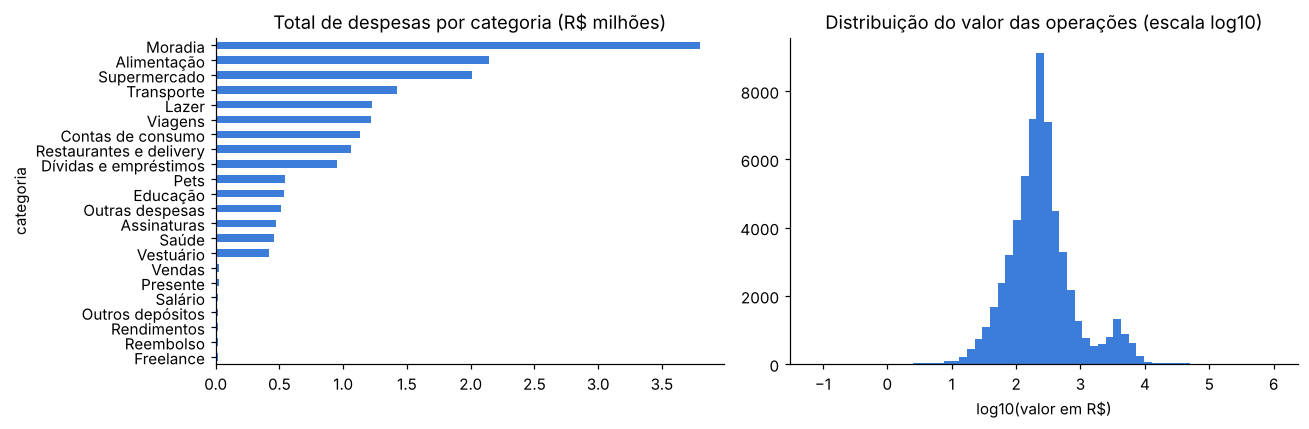

In [6]:
op = operacao.merge(categoria[['idCategoria', 'categoria']], on='idCategoria').merge(tipo_operacao, on='idTipoOperacao')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(op[op.tipoOperacao == 'Despesa'].groupby('categoria').valor.sum().sort_values() / 1e6).plot.barh(ax=ax[0], color='#3b7dd8')
ax[0].set_title('Total de despesas por categoria (R$ milhões)')
ax[0].set_xlabel('')
ax[1].hist(np.log10(op.valor), bins=60, color='#3b7dd8')
ax[1].set_title('Distribuição do valor das operações (escala log10)')
ax[1].set_xlabel('log10(valor em R$)')
plt.tight_layout(); plt.show()

**Hipóteses a testar:**
- **H1** – maior proporção de gastos com lazer e cartão de crédito → mais meses com saldo negativo;
- **H2** – usuários do Plano Gratuito registram menos despesas do que têm, por causa do limite de 10 operações;
- **H3** – usuários com mais XP (mais cursos concluídos) investem uma fração maior da renda.

### 2.4 Verificação da qualidade

In [7]:
hoje = pd.Timestamp('2026-12-31')
cat_tipo = op.merge(categoria[['idCategoria', 'idTipoOperacao']].rename(columns={'idTipoOperacao': 'tipo_da_categoria'}), on='idCategoria')
q1, q3 = op.valor.quantile([0.25, 0.75])
qualidade = pd.Series({
    'Valores nulos': int(op.isna().sum().sum()),
    'Valores não positivos (viola RN-O02)': int((op.valor <= 0).sum()),
    'Datas futuras': int((op.data > hoje).sum()),
    'Categoria incoerente com o tipo (RN-O08)': int((cat_tipo.idTipoOperacao != cat_tipo.tipo_da_categoria).sum()),
    'Valores > 10× a mediana do usuário na categoria (suspeita de digitação)': None,
    'Usuário-meses sem nenhum registro': int(len(usuarios) * len(MESES) - ops_mes.shape[0]),
    'Usuário-meses do Gratuito que bateram o limite de 10': int(((ops_mes.plano == 'gratuito') & (ops_mes.ops >= 10)).sum()),
}, name='ocorrências')
# Suspeita de digitação: valor > 10× a mediana do próprio usuário naquela categoria
med_cat = op.groupby(['usuarioId', 'idCategoria']).valor.transform('median')
qualidade.iloc[4] = int((op.valor > 10 * med_cat).sum())
qualidade.to_frame()

,ocorrências
Valores nulos,0.00
Valores não positivos (viola RN-O02),0.00
Datas futuras,25.00
Categoria incoerente com o tipo (RN-O08),605.00
Valores > 10× a mediana do usuário na categoria (suspeita de digitação),226.00
Usuário-meses sem nenhum registro,226.00
Usuário-meses do Gratuito que bateram o limite de 10,"3,142.00"


## Fase 3 – Preparação dos Dados

Sequência do guia: **Selecionar → Limpar → Construir → Integrar.**

### 3.1 Selecionar (filtrar)

In [8]:
import hashlib
# Pseudonimização (LGPD): o e-mail é trocado por um código; dados pessoais não entram na análise
pseudo = {u: hashlib.sha256(u.encode()).hexdigest()[:10] for u in usuarios.usuarioId}
df = op.drop(columns=['idOperacao']).copy()
df['uid'] = df.usuarioId.map(pseudo)
df = df.drop(columns='usuarioId')
usr = usuarios.assign(uid=usuarios.usuarioId.map(pseudo)).drop(columns='usuarioId')
print(df.columns.tolist())

['data', 'valor', 'idTipoOperacao', 'idCategoria', 'idMetodoPagamento', 'mes', 'categoria', 'tipoOperacao', 'uid']


### 3.2 Limpar (tratar)

In [9]:
antes = len(df)
# mesma ordem da view operacao_limpa do SQL:
# erro de digitação: valor > 10× a mediana do usuário na categoria → divide por 100 (vírgula esquecida).
# Iteração: a 1ª versão usava a mediana geral da categoria e "corrigia" investimentos legítimos de quem
# investe muito; comparar com o histórico do próprio usuário resolveu.
med_cat = df.groupby(['uid', 'idCategoria']).valor.transform('median')
suspeito = df.valor > 10 * med_cat
df.loc[suspeito, 'valor'] = (df.loc[suspeito, 'valor'] / 100).round(2)
# corrige categoria incoerente: despesa lançada em categoria de depósito vai para 'Outras despesas'
tipo_cat = df.idCategoria.map(dict(zip(categoria.idCategoria, categoria.idTipoOperacao)))
incoerente = (df.idTipoOperacao == 2) & (tipo_cat != 2)
df.loc[incoerente, ['idCategoria', 'categoria']] = [cat_id['Outras despesas'], 'Outras despesas']
df = df[df.data <= hoje]                                        # remove datas futuras
print(f'Removidas {antes - len(df)} operações com data futura; '
      f'{incoerente.sum()} categorias corrigidas; {suspeito.sum()} valores corrigidos')

Removidas 25 operações com data futura; 605 categorias corrigidas; 226 valores corrigidos


### 3.3 Construir (derivar atributos) e 3.4 Integrar (mesclar)

In [10]:
g = df.groupby(['uid', 'mes'])
um = pd.DataFrame({
    'total_depositos': g.apply(lambda x: x.valor[x.tipoOperacao == 'Depósito'].sum()),
    'total_despesas': g.apply(lambda x: x.valor[x.tipoOperacao == 'Despesa'].sum()),
    'total_investimentos': g.apply(lambda x: x.valor[x.tipoOperacao == 'Investimento'].sum()),
    'qtd_operacoes': g.size(),
    'perc_credito': g.apply(lambda x: x.valor[(x.tipoOperacao == 'Despesa') & (x.idMetodoPagamento == 1)].sum()
                            / max(x.valor[x.tipoOperacao == 'Despesa'].sum(), 1)),
}).reset_index()
# RN-D02: saldo = depósitos − investimentos − despesas
um['saldo_mes'] = um.total_depositos - um.total_investimentos - um.total_despesas
renda = um.total_depositos.where(um.total_depositos > 0)          # mês sem depósito → razão indefinida (NaN)
um['taxa_investimento'] = um.total_investimentos / renda
um['gasto_sobre_renda'] = um.total_despesas / renda

# percentual de cada categoria de despesa
desp = df[df.tipoOperacao == 'Despesa'].pivot_table(index=['uid', 'mes'], columns='categoria', values='valor',
                                                    aggfunc='sum', fill_value=0)
desp = desp.div(desp.sum(axis=1), axis=0).add_prefix('perc_').reset_index()
um = um.merge(desp, on=['uid', 'mes'], how='left')
um[desp.columns[2:]] = um[desp.columns[2:]].fillna(0)

# integra com plano e engajamento educacional
um = um.merge(usr[['uid', 'plano', 'totalXp', 'cursos_concluidos']], on='uid')
um['premium'] = (um.plano == 'premium').astype(int)
um['limite_atingido'] = ((um.plano == 'gratuito') & (um.qtd_operacoes >= 10)).astype(int)

# atributos de histórico (mês anterior) e alvo (mês seguinte), só entre meses consecutivos
um = um.sort_values(['uid', 'mes'])
for col in ['saldo_mes', 'gasto_sobre_renda']:
    um[f'{col}_ant'] = um.groupby('uid')[col].shift(1)
prox = um.groupby('uid').mes.shift(-1)
um['alvo_negativo_prox_mes'] = (um.groupby('uid').saldo_mes.shift(-1) < 0).astype(float)
um.loc[prox != um.mes + 1, 'alvo_negativo_prox_mes'] = np.nan     # mês seguinte ausente → sem alvo
um['mes'] = um.mes
print(f'Tabela analítica usuário-mês: {um.shape[0]} linhas × {um.shape[1]} colunas')
um.head()

Tabela analítica usuário-mês: 4549 linhas × 33 colunas


,uid,mes,total_depositos,total_despesas,total_investimentos,qtd_operacoes,perc_credito,saldo_mes,taxa_investimento,gasto_sobre_renda,...,perc_Vestuário,perc_Viagens,plano,totalXp,cursos_concluidos,premium,limite_atingido,saldo_mes_ant,gasto_sobre_renda_ant,alvo_negativo_prox_mes
0,00ecfd09ec,2026-01,"2,478.22","1,742.96",0.00,10,0.58,735.26,0.00,0.70,...,0.06,0.09,gratuito,566.00,1,0,1,NaN,NaN,0.00
1,00ecfd09ec,2026-02,"2,662.80","2,075.84",0.00,10,0.77,586.96,0.00,0.78,...,0.00,0.00,gratuito,566.00,1,0,1,735.26,0.70,0.00
2,00ecfd09ec,2026-03,"2,646.72","2,022.28",0.00,10,0.55,624.44,0.00,0.76,...,0.00,0.00,gratuito,566.00,1,0,1,586.96,0.78,0.00
3,00ecfd09ec,2026-04,"2,566.53","1,670.49",0.00,10,0.67,896.04,0.00,0.65,...,0.00,0.09,gratuito,566.00,1,0,1,624.44,0.76,0.00
4,00ecfd09ec,2026-05,"3,876.80","1,769.33",0.00,10,0.67,"2,107.47",0.00,0.46,...,0.00,0.00,gratuito,566.00,1,0,1,896.04,0.65,0.00


### 3.5 Diagrama de dispersão com regressão linear

Antes da modelagem, um diagrama de dispersão verifica a relação entre a **renda mensal média** (depósitos)
e a **despesa mensal média** de cada usuário. A reta é ajustada por regressão linear simples (mínimos
quadrados): despesa = a × renda + b. O R² mostra quanto da variação da despesa a renda explica.

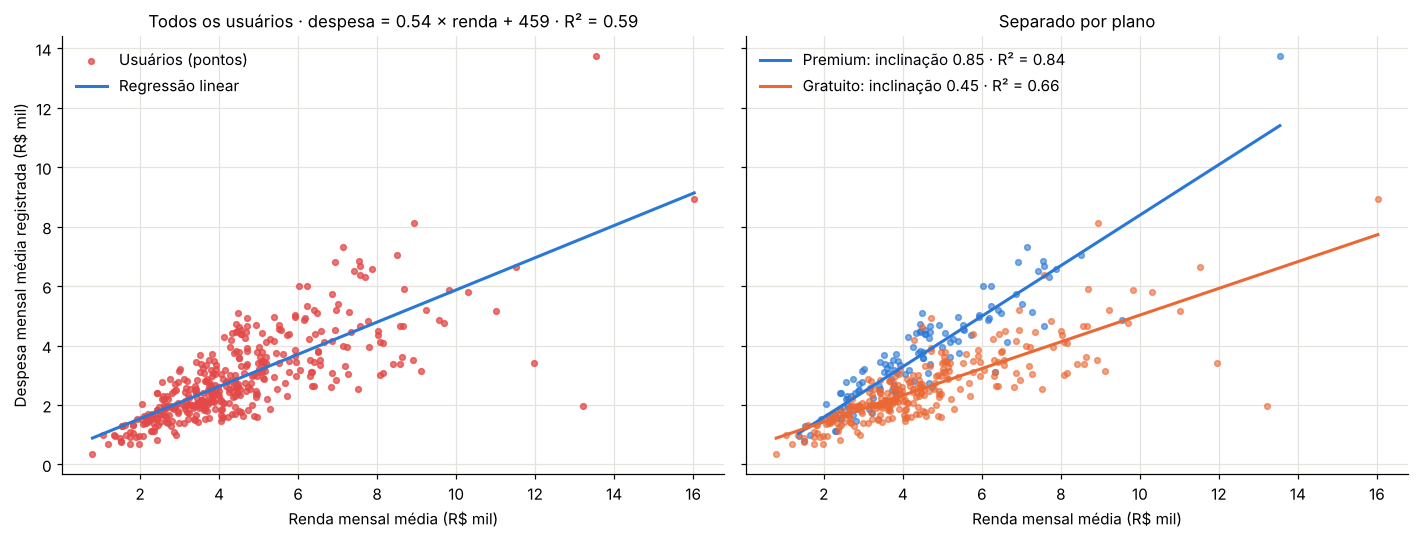

,usuarios,inclinacao,intercepto,R2
grupo,,,,
Todos,400,0.54,458.75,0.59
Premium,122,0.85,-108.93,0.84
Gratuito,278,0.45,530.17,0.66


In [11]:
from sklearn.linear_model import LinearRegression
disp = (um[um.total_depositos > 0].groupby(['uid', 'plano'])
        .agg(renda=('total_depositos', 'mean'), despesa=('total_despesas', 'mean')).reset_index())

def ajustar(g):
    m = LinearRegression().fit(g[['renda']], g.despesa)
    return m, m.coef_[0], m.intercept_, m.score(g[['renda']], g.despesa)

fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
m, a, b, r2 = ajustar(disp)
xs = np.linspace(disp.renda.min(), disp.renda.max(), 50)
ax[0].scatter(disp.renda / 1000, disp.despesa / 1000, s=14, color='#e34948', alpha=0.75, label='Usuários (pontos)')
ax[0].plot(xs / 1000, m.predict(pd.DataFrame({'renda': xs})) / 1000, color='#2a78d6', lw=2, label='Regressão linear')
ax[0].set_title(f'Todos os usuários · despesa = {a:.2f} × renda + {b:,.0f} · R² = {r2:.2f}', fontsize=11)
ax[0].legend(frameon=False)
resumo_reg = [{'grupo': 'Todos', 'usuarios': len(disp), 'inclinacao': a, 'intercepto': b, 'R2': r2}]
for plano_, cor in [('premium', '#2a78d6'), ('gratuito', '#eb6834')]:
    g = disp[disp.plano == plano_]
    m, a, b, r2 = ajustar(g)
    xs = np.linspace(g.renda.min(), g.renda.max(), 50)
    ax[1].scatter(g.renda / 1000, g.despesa / 1000, s=14, color=cor, alpha=0.6)
    ax[1].plot(xs / 1000, m.predict(pd.DataFrame({'renda': xs})) / 1000, color=cor, lw=2,
               label=f'{plano_.capitalize()}: inclinação {a:.2f} · R² = {r2:.2f}')
    resumo_reg.append({'grupo': plano_.capitalize(), 'usuarios': len(g), 'inclinacao': a, 'intercepto': b, 'R2': r2})
ax[1].set_title('Separado por plano', fontsize=11); ax[1].legend(frameon=False)
for a_ in ax:
    a_.set_xlabel('Renda mensal média (R$ mil)'); a_.grid(color='#e4e3de', lw=0.8); a_.set_axisbelow(True)
ax[0].set_ylabel('Despesa mensal média registrada (R$ mil)')
plt.tight_layout(); plt.show()
resumo_reg = pd.DataFrame(resumo_reg).set_index('grupo')
resumo_reg

**Leitura:** a relação é positiva e aproximadamente linear: quem ganha mais gasta mais. No Plano Premium,
cada R$ 1,00 a mais de renda vem acompanhado de cerca de R$ 0,85 a mais de despesa, e a renda explica a maior
parte da variação. No Plano Gratuito, a inclinação cai quase pela metade: não porque esses usuários gastem
menos, mas porque o limite de 10 operações por mês deixa parte das despesas sem registro. O diagrama confirma
visualmente a hipótese H2 e justifica tratar os dois planos separadamente na avaliação.

## Fase 4 – Modelagem

### 4.1 Clusterização: perfis de consumo (K-means)

Cada usuário é resumido pela média dos seus meses. Os atributos são padronizados (StandardScaler) e testamos k de 3 a 6.

,inercia,silhueta,menor_cluster_%
k,,,
3,"3,541.11",0.34,13.25
4,"2,922.81",0.32,13.25
5,"2,513.86",0.32,8.50
6,"2,343.98",0.33,0.25


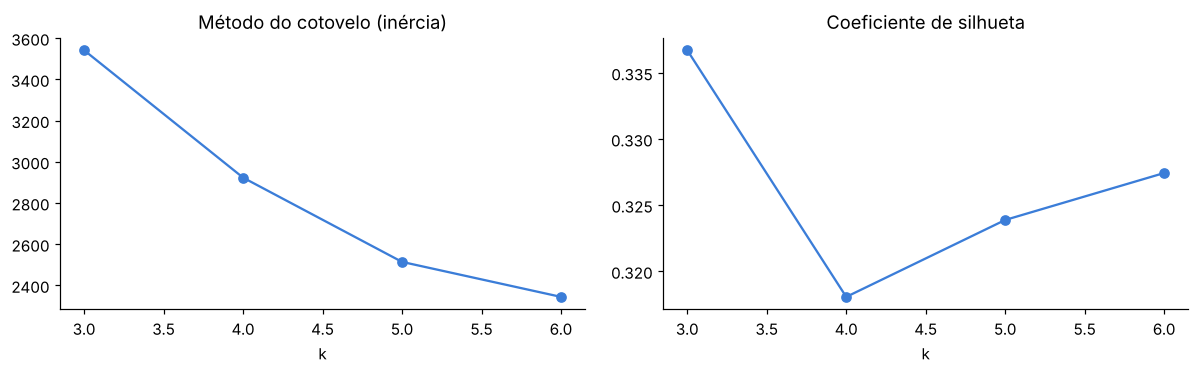

In [12]:
cols_perc = [c for c in um.columns if c.startswith('perc_') and c != 'perc_credito']
cols_cluster = cols_perc + ['perc_credito', 'taxa_investimento', 'gasto_sobre_renda']
perfil_usr = um.groupby('uid')[cols_cluster].mean()
perfil_usr = perfil_usr.fillna(perfil_usr.median())
X_clu = StandardScaler().fit_transform(perfil_usr)

resultados = []
for k in range(3, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_clu)
    resultados.append({'k': k, 'inercia': km.inertia_, 'silhueta': silhouette_score(X_clu, km.labels_),
                       'menor_cluster_%': np.bincount(km.labels_).min() / len(X_clu) * 100})
res_k = pd.DataFrame(resultados).set_index('k')
display(res_k)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
res_k.inercia.plot(marker='o', ax=ax[0], title='Método do cotovelo (inércia)', color='#3b7dd8')
res_k.silhueta.plot(marker='o', ax=ax[1], title='Coeficiente de silhueta', color='#3b7dd8')
plt.tight_layout(); plt.show()

In [13]:
K = int(res_k.silhueta.idxmax())
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X_clu)
perfil_usr['cluster'] = km.labels_
centros = perfil_usr.groupby('cluster')[['perc_Moradia', 'perc_Lazer', 'perc_Restaurantes e delivery',
                                         'perc_Dívidas e empréstimos', 'perc_credito', 'taxa_investimento',
                                         'gasto_sobre_renda']].mean()
centros['usuarios'] = perfil_usr.cluster.value_counts().sort_index()

# Nomeia cada cluster pelo traço que mais o diferencia (regra simples e explicável)
nomes_cluster, livres = {}, list(centros.index)
for perfil, traco in [('Poupador/investidor', centros.taxa_investimento),
                      ('Endividado', centros['perc_Dívidas e empréstimos']),
                      ('Lazer e crédito elevados', centros.perc_Lazer + centros['perc_Restaurantes e delivery'])]:
    if livres:
        c = traco.loc[livres].idxmax(); nomes_cluster[c] = perfil; livres.remove(c)
for c in livres:
    nomes_cluster[c] = 'Consumo essencial'
centros['perfil'] = centros.index.map(nomes_cluster)
display(centros)

,perc_Moradia,perc_Lazer,perc_Restaurantes e delivery,perc_Dívidas e empréstimos,perc_credito,taxa_investimento,gasto_sobre_renda,usuarios,perfil
cluster,,,,,,,,,
0,0.19,0.02,0.02,0.24,0.54,0.00,0.81,53,Endividado
1,0.24,0.03,0.03,0.01,0.28,0.12,0.59,227,Poupador/investidor
2,0.17,0.13,0.13,0.01,0.65,0.02,0.74,120,Lazer e crédito elevados


### 4.2 Classificação: risco de saldo negativo no mês seguinte

**Design de teste temporal:** treino com meses de janeiro a agosto e teste com setembro a novembro
(prevendo outubro a dezembro). Assim o modelo nunca "vê o futuro".

In [14]:
feat = ['gasto_sobre_renda', 'taxa_investimento', 'perc_credito', 'perc_Lazer', 'perc_Restaurantes e delivery',
        'perc_Dívidas e empréstimos', 'perc_Viagens', 'qtd_operacoes', 'saldo_mes', 'saldo_mes_ant',
        'gasto_sobre_renda_ant', 'premium', 'limite_atingido', 'totalXp']
dados = um.dropna(subset=['alvo_negativo_prox_mes']).copy()
dados[feat] = dados[feat].fillna(dados[feat].median())
treino = dados[dados.mes <= pd.Period('2026-08', 'M')]
teste = dados[dados.mes > pd.Period('2026-08', 'M')]
Xtr, ytr, Xte, yte = treino[feat], treino.alvo_negativo_prox_mes, teste[feat], teste.alvo_negativo_prox_mes
print(f'Treino: {len(treino)} linhas ({ytr.mean():.0%} negativos) · Teste: {len(teste)} linhas ({yte.mean():.0%} negativos)')

modelos = {
    'Regressão logística (base)': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000)),
    'Árvore de decisão': DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', random_state=SEED),
}
linhas = []
for nome, m in modelos.items():
    m.fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]
    pred = (p >= 0.5).astype(int)
    linhas.append({'modelo': nome, 'recall': recall_score(yte, pred), 'precisão': precision_score(yte, pred),
                   'F1': f1_score(yte, pred), 'AUC-ROC': roc_auc_score(yte, p)})
metricas = pd.DataFrame(linhas).set_index('modelo')
metricas

Treino: 2877 linhas (9% negativos) · Teste: 1066 linhas (11% negativos)


,recall,precisão,F1,AUC-ROC
modelo,,,,
Regressão logística (base),0.88,0.34,0.49,0.90
Árvore de decisão,0.87,0.33,0.48,0.87
Random Forest,0.74,0.42,0.54,0.90


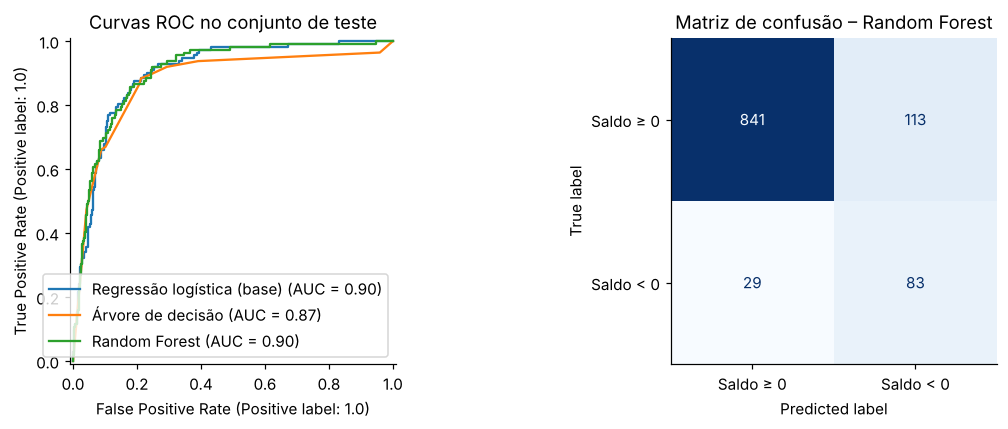

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for nome, m in modelos.items():
    RocCurveDisplay.from_estimator(m, Xte, yte, name=nome, ax=ax[0])
ax[0].set_title('Curvas ROC no conjunto de teste')
melhor = metricas.F1.idxmax()
ConfusionMatrixDisplay(confusion_matrix(yte, modelos[melhor].predict(Xte)),
                       display_labels=['Saldo ≥ 0', 'Saldo < 0']).plot(ax=ax[1], colorbar=False, cmap='Blues')
ax[1].set_title(f'Matriz de confusão – {melhor}')
plt.tight_layout(); plt.show()

|--- qtd_operacoes <= 14.50
|   |--- perc_Dívidas e empréstimos <= 0.06
|   |   |--- totalXp <= 14.00
|   |   |   |--- taxa_investimento <= 0.04
|   |   |   |   |--- class: 1.0
|   |   |   |--- taxa_investimento >  0.04
|   |   |   |   |--- class: 0.0
|   |   |--- totalXp >  14.00
|   |   |   |--- gasto_sobre_renda <= 0.76
|   |   |   |   |--- class: 0.0
|   |   |   |--- gasto_sobre_renda >  0.76
|   |   |   |   |--- class: 0.0
|   |--- perc_Dívidas e empréstimos >  0.06
|   |   |--- saldo_mes_ant <= 632.12
|   |   |   |--- perc_credito <= 0.52
|   |   |   |   |--- class: 1.0
|   |   |   |--- perc_credito >  0.52
|   |   |   |   |--- class: 0.0
|   |   |--- saldo_mes_ant >  632.12
|   |   |   |--- perc_Dívidas e empréstimos <= 0.06
|   |   |   |   |--- class: 1.0
|   |   |   |--- perc_Dívidas e empréstimos >  0.06
|   |   |   |   |--- class: 0.0
|--- qtd_operacoes >  14.50
|   |--- gasto_sobre_renda <= 0.60
|   |   |--- saldo_mes_ant <= 145.51
|   |   |   |--- saldo_mes_ant <= 87.21
| 

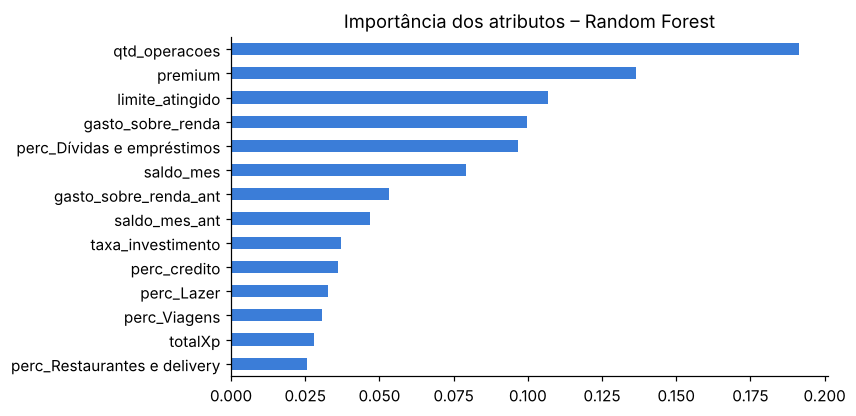

In [16]:
# Regras da árvore: podem ser explicadas ao usuário no alerta
print(export_text(modelos['Árvore de decisão'], feature_names=feat, decimals=2))
imp = pd.Series(modelos['Random Forest'].feature_importances_, index=feat).sort_values()
imp.plot.barh(figsize=(7, 4), color='#3b7dd8', title='Importância dos atributos – Random Forest'); plt.show()

## Fase 5 – Avaliação

Impacto real > precisão técnica: os modelos são confrontados com os critérios de sucesso da Fase 1.

In [17]:
crit = pd.DataFrame([
    ['Silhueta do K-means > 0,25', f'{res_k.loc[K, "silhueta"]:.2f}', res_k.loc[K, 'silhueta'] > 0.25],
    ['Menor cluster ≥ 5% dos usuários', f'{res_k.loc[K, "menor_cluster_%"]:.1f}%', res_k.loc[K, 'menor_cluster_%'] >= 5],
    [f'Recall ≥ 0,70 ({melhor})', f'{metricas.loc[melhor, "recall"]:.2f}', metricas.loc[melhor, 'recall'] >= 0.70],
    ['Supera o modelo base em F1', f'{metricas.loc[melhor, "F1"]:.2f} vs {metricas.iloc[0]["F1"]:.2f}',
     metricas.loc[melhor, 'F1'] >= metricas.iloc[0]['F1']],
], columns=['critério', 'resultado', 'atendido'])
display(crit)

# Validação extra possível só com dados simulados: o K-means reencontrou os perfis ocultos?
oculto = usr.set_index('uid').loc[perfil_usr.index, 'perfil_oculto']
print(f'Índice de Rand ajustado (clusters × perfis ocultos): {adjusted_rand_score(oculto, perfil_usr.cluster):.2f}')
display(pd.crosstab(perfil_usr.cluster.map(centros.perfil), oculto))

,critério,resultado,atendido
0,"Silhueta do K-means > 0,25",0.34,True
1,Menor cluster ≥ 5% dos usuários,13.2%,True
2,"Recall ≥ 0,70 (Random Forest)",0.74,True
3,Supera o modelo base em F1,0.54 vs 0.49,True


Índice de Rand ajustado (clusters × perfis ocultos): 0.67


perfil_oculto,endividado,essencial,lazer_credito,poupador
cluster,,,,
Endividado,53,0,0,0
Lazer e crédito elevados,0,0,120,0
Poupador/investidor,0,139,0,88


**Iteração (volta à Fase 4):** com o k escolhido pela silhueta, o K-means pode juntar perfis parecidos.
Testamos k = 4 para ver se os perfis ficam mais separados e mais úteis para a recomendação.

In [18]:
km4 = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(X_clu)
print(f'k=4 → silhueta {silhouette_score(X_clu, km4.labels_):.2f} · '
      f'Rand ajustado com os perfis ocultos {adjusted_rand_score(oculto, km4.labels_):.2f}')
pd.crosstab(pd.Series(km4.labels_, index=perfil_usr.index, name='cluster (k=4)'), oculto)

k=4 → silhueta 0.32 · Rand ajustado com os perfis ocultos 0.60


perfil_oculto,endividado,essencial,lazer_credito,poupador
cluster (k=4),,,,
0,0,89,0,61
1,0,0,120,0
2,0,50,0,27
3,53,0,0,0


**Leitura da iteração:** k = 4 não resolveu, pois dividiu os mesmos usuários de outra forma. Os perfis
"essencial" e "poupador" gastam de modo parecido e se diferenciam quase só pela taxa de investimento, que fica
diluída entre 18 atributos. A próxima volta no ciclo seria na Fase 3: reduzir os atributos de categoria
(por exemplo, agrupando em essenciais × supérfluos) ou dar mais peso à taxa de investimento.

In [19]:
# Revisão de falhas: o modelo funciona igual para os dois planos?
teste_aval = teste.assign(pred=modelos[melhor].predict(Xte))
por_plano = teste_aval.groupby('plano').apply(lambda x: pd.Series({
    'linhas': len(x), 'recall': recall_score(x.alvo_negativo_prox_mes, x.pred),
    'F1': f1_score(x.alvo_negativo_prox_mes, x.pred)}))
por_plano

,linhas,recall,F1
plano,,,
gratuito,737.00,0.10,0.17
premium,329.00,0.80,0.55


**Leitura:** o modelo vai bem no Plano Premium, mas quase não detecta o risco no Plano Gratuito. A causa é o
limite de 10 operações por mês: as despesas menores ficam sem registro e o mês parece mais saudável do que é
(hipótese H2). Pelo CRISP-DM, isso leva de volta às Fases 2 e 3: enriquecer a base desses usuários ou treinar
um modelo separado. Esta é a **nova pergunta** que a avaliação revela.

## Fase 6 – Implementação

Protótipo do job mensal: para cada usuário, grava o perfil, o curso recomendado e a probabilidade de saldo
negativo, no formato das novas entidades `PerfilUsuario` e `AlertaRisco` propostas no trabalho. A recomendação
respeita a regra RN-P05: no Plano Gratuito só os cursos 1 e 2 estão liberados.

In [20]:
nivel_por_perfil = {'Consumo essencial': 'Fundamentos', 'Lazer e crédito elevados': 'Fundamentos',
                    'Endividado': 'Fundamentos', 'Poupador/investidor': 'Construção de Patrimônio'}
cursos_por_nivel = {'Fundamentos': [1, 2], 'Construção de Patrimônio': [3, 4], 'Liberdade Financeira': [5, 6]}

def recomendar_curso(perfil, concluidos, plano):
    ordem = cursos_por_nivel[nivel_por_perfil[perfil]] + [c for c in range(1, 7)]
    liberados = [1, 2] if plano == 'gratuito' else list(range(1, 7))
    for c in ordem:
        if c > concluidos and c in liberados:      # cursos são feitos em sequência (ordemCurso)
            return f'Curso {c}'
    return 'Todos os cursos liberados já foram concluídos'

ultimo = um.sort_values('mes').groupby('uid').tail(1).set_index('uid')
ultimo[feat] = ultimo[feat].fillna(dados[feat].median())
saida = pd.DataFrame({
    'perfil': perfil_usr.cluster.map(centros.perfil),
    'plano': ultimo.plano,
    'cursos_concluidos': ultimo.cursos_concluidos,
    'prob_saldo_negativo': modelos[melhor].predict_proba(ultimo[feat])[:, 1].round(2),
})
saida['curso_recomendado'] = [recomendar_curso(p, c, pl) for p, c, pl in
                              zip(saida.perfil, saida.cursos_concluidos, saida.plano)]
saida['alerta'] = saida.prob_saldo_negativo >= 0.5
print(f'{saida.alerta.sum()} de {len(saida)} usuários receberiam alerta de risco em janeiro/2027')
saida.head(10)

70 de 400 usuários receberiam alerta de risco em janeiro/2027


,perfil,plano,cursos_concluidos,prob_saldo_negativo,curso_recomendado,alerta
uid,,,,,,
00ecfd09ec,Endividado,gratuito,1,0.11,Curso 2,False
012409cfda,Poupador/investidor,gratuito,0,0.20,Curso 1,False
01cf4db389,Lazer e crédito elevados,gratuito,1,0.10,Curso 2,False
01cf56077d,Endividado,gratuito,1,0.02,Curso 2,False
02040d88eb,Poupador/investidor,gratuito,0,0.93,Curso 1,True
02b10b8635,Poupador/investidor,premium,0,0.01,Curso 3,False
040d605563,Poupador/investidor,gratuito,0,0.01,Curso 1,False
07051e8f58,Endividado,premium,1,0.16,Curso 2,False
072766c1f2,Endividado,gratuito,0,0.36,Curso 1,False


In [21]:
# Monitoramento (obsolescência do modelo): compara a distribuição dos gastos do último trimestre com a do treino
cols_mon = ['gasto_sobre_renda', 'perc_credito', 'perc_Lazer', 'taxa_investimento']
drift = pd.DataFrame({'treino (jan–ago)': treino[cols_mon].mean(), 'recente (set–nov)': teste[cols_mon].mean()})
drift['variação %'] = (drift.iloc[:, 1] / drift.iloc[:, 0] - 1) * 100
drift

,treino (jan–ago),recente (set–nov),variação %
gasto_sobre_renda,0.67,0.66,-0.92
perc_credito,0.43,0.42,-2.50
perc_Lazer,0.06,0.06,-3.67
taxa_investimento,0.07,0.09,36.69


## Dashboard (Pandas + Matplotlib + Seaborn)

No lugar do Power BI, o dashboard é montado em Python com as bibliotecas de visualização da disciplina:
**Pandas** agrega os dados, **Seaborn** desenha os gráficos e **Matplotlib** organiza as páginas. São três
páginas, salvas como imagem na pasta `Dashboard/`: visão geral financeira, resultados dos modelos (P1 e P2) e
o diagrama de dispersão com regressão linear.

In [22]:
import seaborn as sns
from matplotlib.ticker import FuncFormatter
os.makedirs('Dashboard', exist_ok=True) if 'os' in dir() else None
import os
os.makedirs('Dashboard', exist_ok=True)

AZUL, LARANJA, VERDE, VERMELHO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
TINTA, TINTA2, GRADE, FUNDO = '#0b0b0b', '#52514e', '#e4e3de', '#fcfcfb'
sns.set_theme(style='whitegrid', rc={'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'grid.color': GRADE,
                                     'axes.edgecolor': GRADE, 'axes.titleweight': 'bold', 'axes.titlesize': 13,
                                     'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False})
br = lambda v, d=0: f'{v:,.{d}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
mi = lambda v: f'R$ {br(v / 1e6, 1)} mi'

def cabecalho(fig, titulo, sub):
    fig.text(0.035, 0.955, titulo, fontsize=20, fontweight='bold', color=TINTA)
    fig.text(0.035, 0.925, sub, fontsize=11, color=TINTA2)
    fig.text(0.965, 0.955, 'DADOS SIMULADOS', fontsize=10, fontweight='bold', color=TINTA2, ha='right')

def cartao(fig, x, rotulo, valor, w=0.145):
    ax = fig.add_axes([x, 0.80, w, 0.09]); ax.axis('off')
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor='white', edgecolor=GRADE))
    ax.text(0.07, 0.68, rotulo, fontsize=10.5, color=TINTA2, transform=ax.transAxes)
    ax.text(0.07, 0.22, valor, fontsize=19, fontweight='bold', color=TINTA, transform=ax.transAxes)

def rotular_barras(ax, fmt, horizontal=True):
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt(v) for v in c.datavalues], padding=4, fontsize=10, color=TINTA)
    if horizontal:
        ax.set_xlim(0, ax.get_xlim()[1] * 1.18); ax.xaxis.set_visible(False); ax.grid(False)
    ax.set_xlabel(''); ax.set_ylabel('')

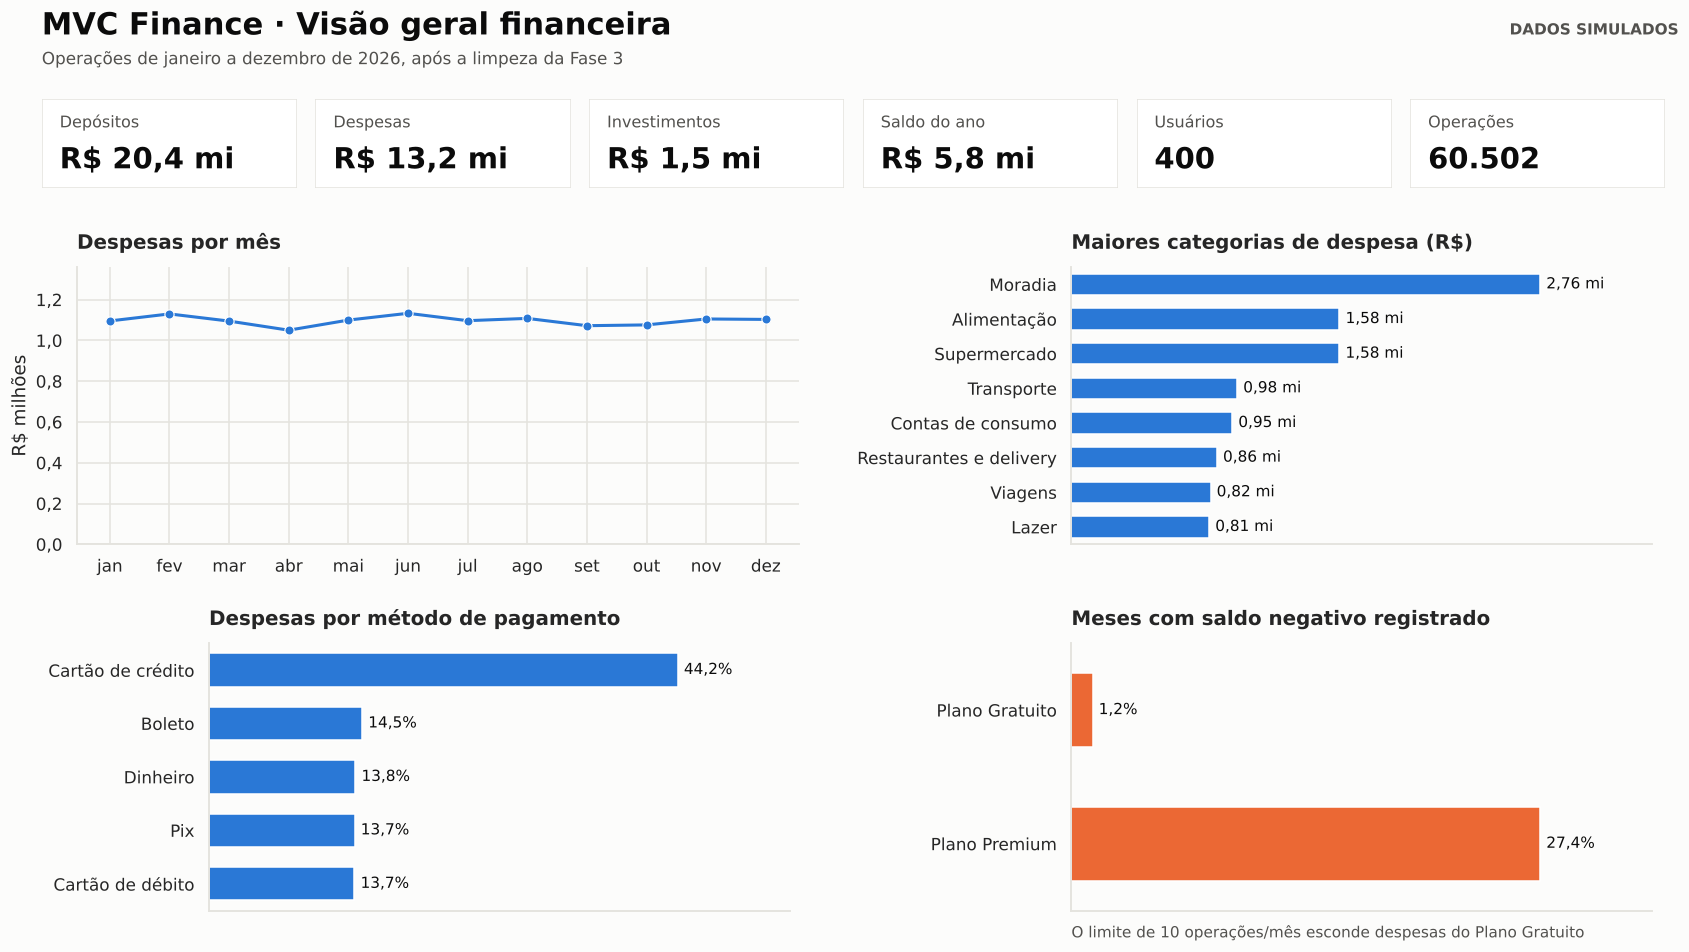

In [23]:
# ---------- Página 1: visão geral financeira (base limpa) ----------
tot = df.groupby('tipoOperacao').valor.sum()
desp_df = df[df.tipoOperacao == 'Despesa']
por_mes = desp_df.groupby(desp_df.mes.astype(str)).valor.sum().reset_index()
por_mes['mes_nome'] = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez'][:len(por_mes)]
top_cat = desp_df.groupby('categoria').valor.sum().nlargest(8).reset_index()
nomes_met = dict(zip(metodo_pagamento.idMetodoPagamento, metodo_pagamento.tipoPagamento))
por_met = (desp_df.groupby(desp_df.idMetodoPagamento.map(nomes_met)).valor.sum() / desp_df.valor.sum() * 100)
por_met = por_met.sort_values(ascending=False).rename_axis('metodo').reset_index(name='perc')
neg_plano = (um.assign(neg=um.saldo_mes < 0).groupby('plano').neg.mean() * 100).reset_index()
neg_plano['plano'] = neg_plano.plano.map({'gratuito': 'Plano Gratuito', 'premium': 'Plano Premium'})

fig = plt.figure(figsize=(16, 9))
cabecalho(fig, 'MVC Finance · Visão geral financeira', 'Operações de janeiro a dezembro de 2026, após a limpeza da Fase 3')
for i, (r, v) in enumerate([('Depósitos', mi(tot['Depósito'])), ('Despesas', mi(tot['Despesa'])),
                            ('Investimentos', mi(tot['Investimento'])),
                            ('Saldo do ano', mi(tot['Depósito'] - tot['Despesa'] - tot['Investimento'])),
                            ('Usuários', br(df.uid.nunique())), ('Operações', br(len(df)))]):
    cartao(fig, 0.035 + i * 0.1555, r, v)

ax = fig.add_axes([0.055, 0.44, 0.41, 0.28])
sns.lineplot(data=por_mes, x='mes_nome', y=por_mes.valor / 1e6, marker='o', color=AZUL, lw=2, ax=ax)
ax.set_ylim(0, por_mes.valor.max() / 1e6 * 1.2); ax.set_xlabel(''); ax.set_ylabel('R$ milhões')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 1))); ax.set_title('Despesas por mês', pad=12)

ax = fig.add_axes([0.62, 0.44, 0.33, 0.28])
sns.barplot(data=top_cat, y='categoria', x=top_cat.valor / 1e6, color=AZUL, width=0.62, saturation=1, ax=ax)
rotular_barras(ax, lambda v: br(v, 2) + ' mi'); ax.set_title('Maiores categorias de despesa (R$)', pad=12)

ax = fig.add_axes([0.13, 0.07, 0.33, 0.27])
sns.barplot(data=por_met, y='metodo', x='perc', color=AZUL, width=0.62, saturation=1, ax=ax)
rotular_barras(ax, lambda v: br(v, 1) + '%'); ax.set_title('Despesas por método de pagamento', pad=12)

ax = fig.add_axes([0.62, 0.07, 0.33, 0.27])
sns.barplot(data=neg_plano, y='plano', x='neg', color=LARANJA, width=0.55, saturation=1, ax=ax)
rotular_barras(ax, lambda v: br(v, 1) + '%'); ax.set_title('Meses com saldo negativo registrado', pad=12)
ax.text(0, -0.1, 'O limite de 10 operações/mês esconde despesas do Plano Gratuito', fontsize=10, color=TINTA2, transform=ax.transAxes)
fig.savefig('Dashboard/01_visao_geral.png', dpi=110); plt.show()

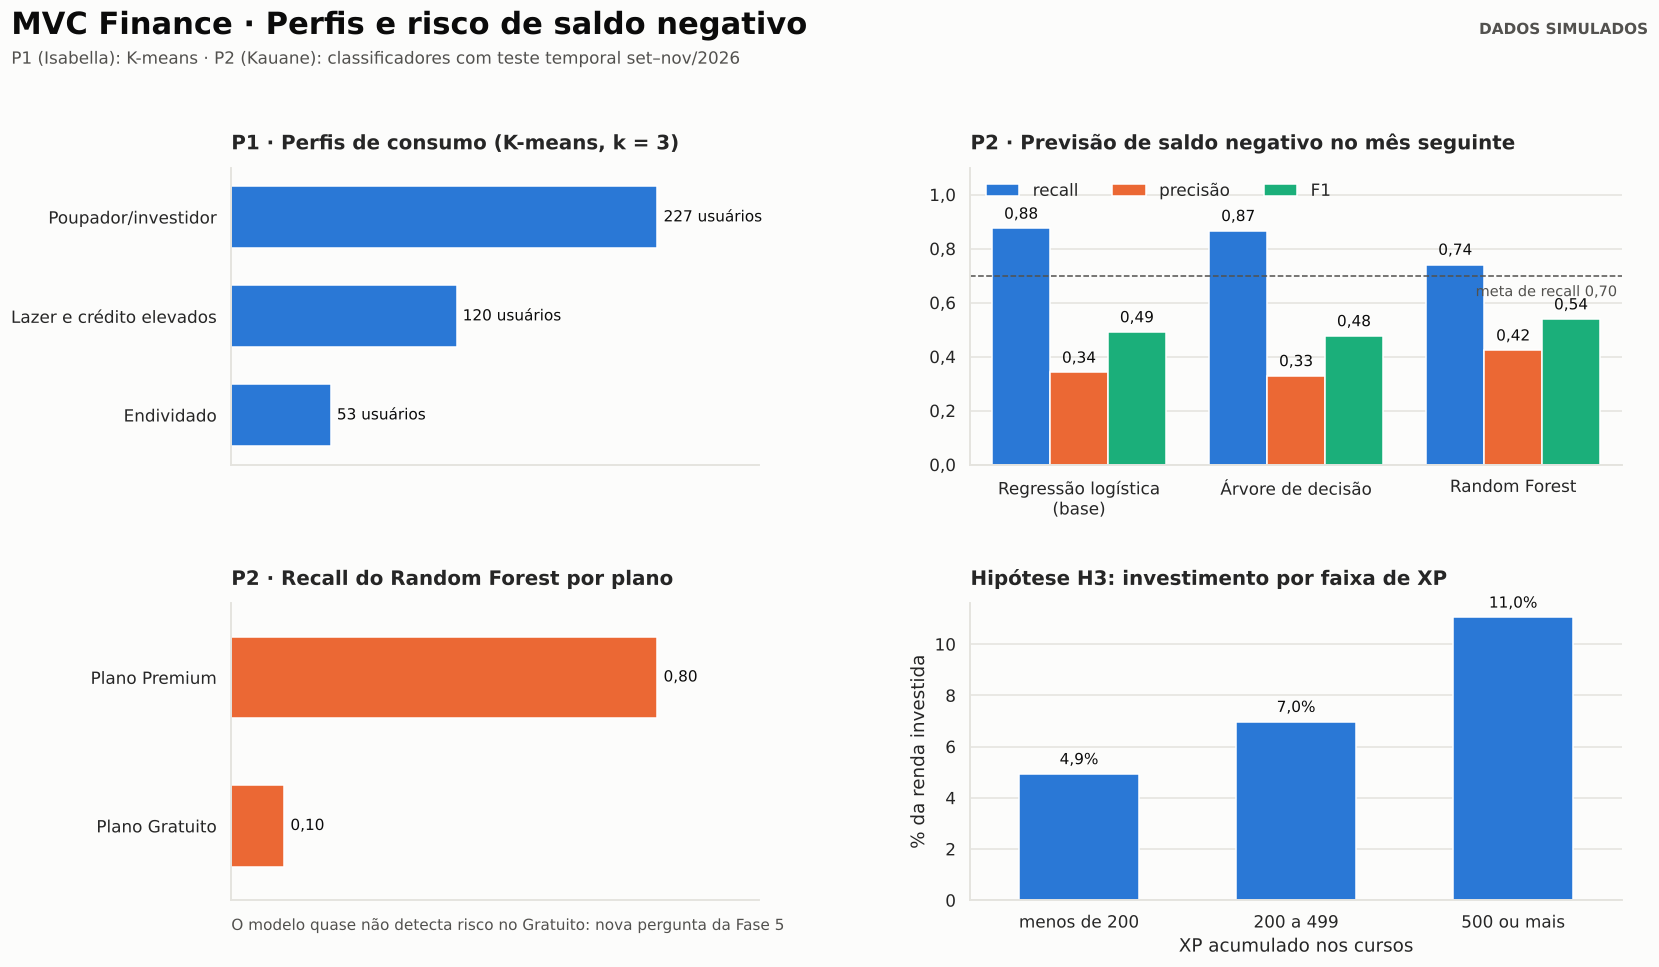

In [24]:
# ---------- Página 2: perfis (P1 – Isabella) e risco de saldo negativo (P2 – Kauane) ----------
contagem = perfil_usr.cluster.map(centros.perfil).value_counts().rename_axis('perfil').reset_index(name='usuarios')
metr_long = metricas[['recall', 'precisão', 'F1']].reset_index().melt(id_vars='modelo', var_name='métrica', value_name='valor')
metr_long['modelo'] = metr_long.modelo.str.replace(' (base)', '\n(base)', regex=False)
rec_plano = por_plano.reset_index()
rec_plano['plano'] = rec_plano.plano.map({'gratuito': 'Plano Gratuito', 'premium': 'Plano Premium'})
faixa = pd.cut(usr.set_index('uid').totalXp, [-1, 199, 499, np.inf], labels=['menos de 200', '200 a 499', '500 ou mais'])
inv_xp = (df.assign(faixa=df.uid.map(faixa)).groupby(['faixa', 'tipoOperacao'], observed=True).valor.sum().unstack())
inv_xp = (inv_xp['Investimento'] / inv_xp['Depósito'] * 100).reset_index(name='perc')

fig = plt.figure(figsize=(16, 9))
cabecalho(fig, 'MVC Finance · Perfis e risco de saldo negativo', 'P1 (Isabella): K-means · P2 (Kauane): classificadores com teste temporal set–nov/2026')

ax = fig.add_axes([0.16, 0.52, 0.30, 0.30])
sns.barplot(data=contagem, y='perfil', x='usuarios', color=AZUL, width=0.62, saturation=1, ax=ax)
rotular_barras(ax, lambda v: f'{v:.0f} usuários'); ax.set_title(f'P1 · Perfis de consumo (K-means, k = {K})', pad=12)

ax = fig.add_axes([0.58, 0.52, 0.37, 0.30])
sns.barplot(data=metr_long, x='modelo', y='valor', hue='métrica', palette=[AZUL, LARANJA, VERDE], saturation=1, ax=ax)
rotular_barras(ax, lambda v: br(v, 2), horizontal=False)
ax.axhline(0.70, color=TINTA2, lw=1, ls='--'); ax.set_ylim(0, 1.1)
ax.text(ax.get_xlim()[1], 0.665, 'meta de recall 0,70 ', fontsize=9.5, color=TINTA2, ha='right', va='top')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 1)))
ax.legend(frameon=False, ncol=3, loc='upper left', title=None); ax.set_title('P2 · Previsão de saldo negativo no mês seguinte', pad=12)

ax = fig.add_axes([0.16, 0.08, 0.30, 0.30])
sns.barplot(data=rec_plano, y='plano', x='recall', color=LARANJA, width=0.55, saturation=1, order=['Plano Premium', 'Plano Gratuito'], ax=ax)
rotular_barras(ax, lambda v: br(v, 2)); ax.set_title(f'P2 · Recall do {melhor} por plano', pad=12)
ax.text(0, -0.1, 'O modelo quase não detecta risco no Gratuito: nova pergunta da Fase 5', fontsize=10, color=TINTA2, transform=ax.transAxes)

ax = fig.add_axes([0.58, 0.08, 0.37, 0.30])
sns.barplot(data=inv_xp, x='faixa', y='perc', color=AZUL, width=0.55, saturation=1, ax=ax)
rotular_barras(ax, lambda v: br(v, 1) + '%', horizontal=False)
ax.set_xlabel('XP acumulado nos cursos'); ax.set_ylabel('% da renda investida')
ax.set_title('Hipótese H3: investimento por faixa de XP', pad=12)
fig.savefig('Dashboard/02_modelos.png', dpi=110); plt.show()

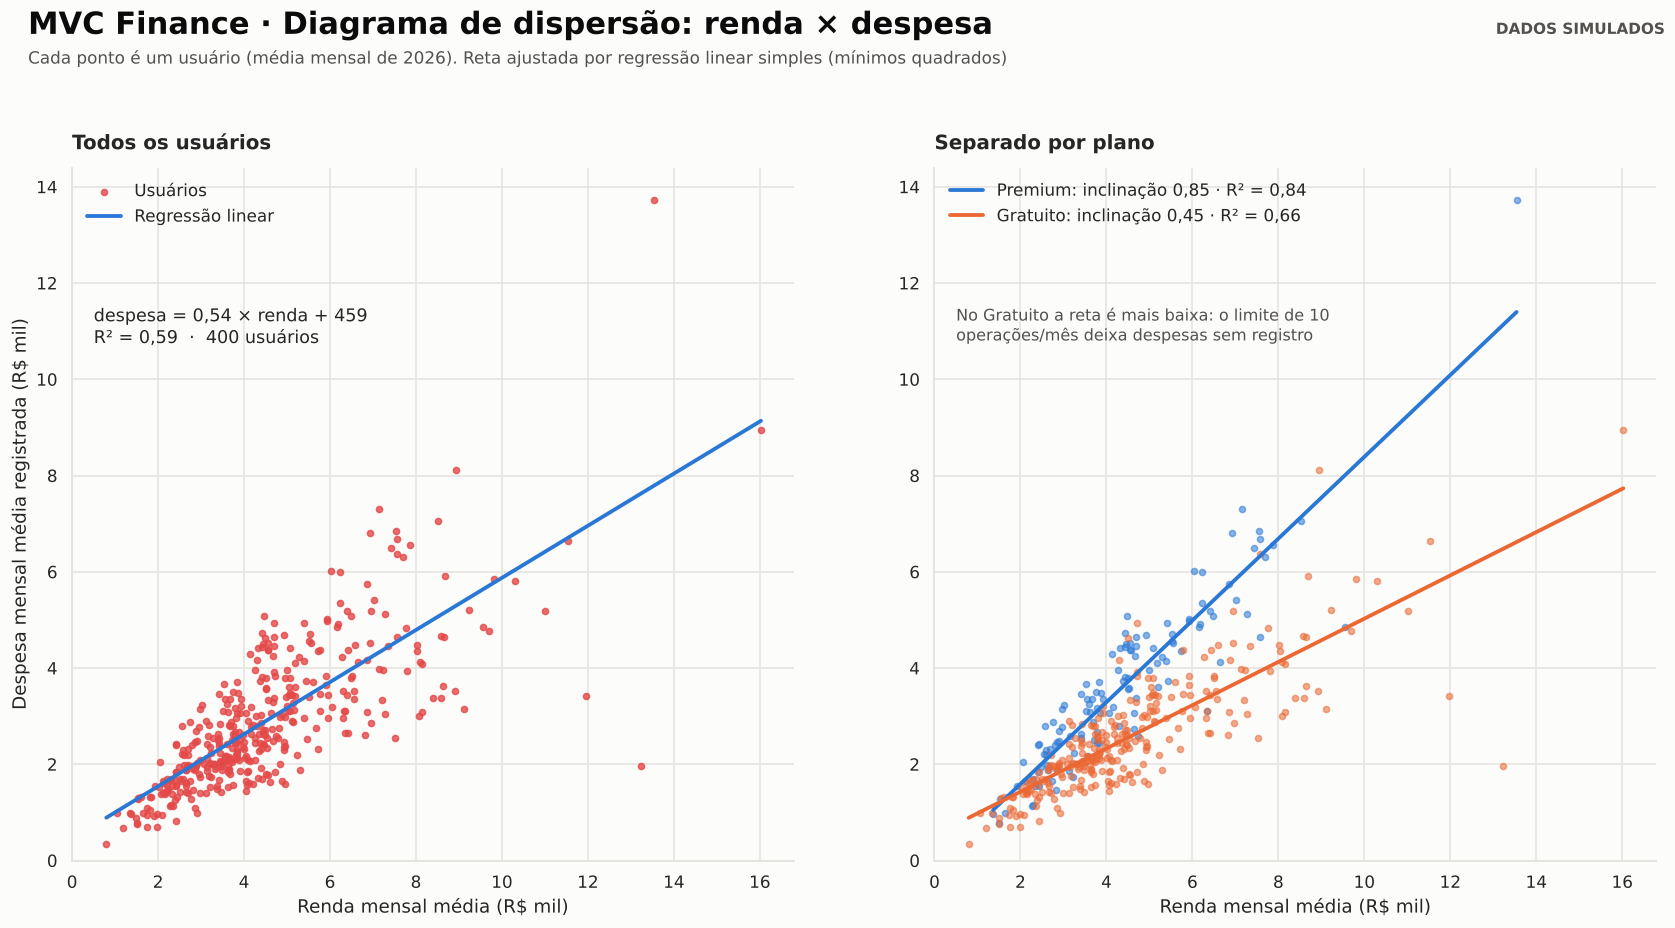

In [25]:
# ---------- Página 3: diagrama de dispersão com regressão linear (sns.regplot) ----------
fig = plt.figure(figsize=(16, 9))
cabecalho(fig, 'MVC Finance · Diagrama de dispersão: renda × despesa',
          'Cada ponto é um usuário (média mensal de 2026). Reta ajustada por regressão linear simples (mínimos quadrados)')
d = disp.assign(renda_mil=disp.renda / 1000, despesa_mil=disp.despesa / 1000)

ax = fig.add_axes([0.06, 0.12, 0.41, 0.70])
sns.regplot(data=d, x='renda_mil', y='despesa_mil', ci=None, ax=ax, truncate=True,
            scatter_kws={'s': 16, 'color': VERMELHO, 'alpha': 0.8, 'label': 'Usuários'},
            line_kws={'color': AZUL, 'lw': 2.5, 'label': 'Regressão linear'})
r = resumo_reg.loc['Todos']
ax.text(0.03, 0.80, f'despesa = {br(r.inclinacao, 2)} × renda + {br(r.intercepto)}\nR² = {br(r.R2, 2)}  ·  {int(r.usuarios)} usuários',
        transform=ax.transAxes, fontsize=11.5, va='top')
ax.collections[0].set_label('Usuários')
ax.legend(frameon=False, loc='upper left', fontsize=11); ax.set_title('Todos os usuários', pad=12)

ax2 = fig.add_axes([0.55, 0.12, 0.41, 0.70], sharey=ax)
for plano_, cor, nome in [('premium', AZUL, 'Premium'), ('gratuito', LARANJA, 'Gratuito')]:
    r = resumo_reg.loc[nome]
    sns.regplot(data=d[d.plano == plano_], x='renda_mil', y='despesa_mil', ci=None, ax=ax2, truncate=True,
                scatter_kws={'s': 16, 'color': cor, 'alpha': 0.55},
                line_kws={'color': cor, 'lw': 2.5, 'label': f'{nome}: inclinação {br(r.inclinacao, 2)} · R² = {br(r.R2, 2)}'})
ax2.legend(frameon=False, loc='upper left', fontsize=11); ax2.set_title('Separado por plano', pad=12)
ax2.text(0.03, 0.80, 'No Gratuito a reta é mais baixa: o limite de 10\noperações/mês deixa despesas sem registro',
         transform=ax2.transAxes, fontsize=10.5, color=TINTA2, va='top')
for a_ in (ax, ax2):
    a_.set_xlabel('Renda mensal média (R$ mil)'); a_.set_xlim(left=0)
ax.set_ylabel('Despesa mensal média registrada (R$ mil)'); ax2.set_ylabel(''); ax.set_ylim(bottom=0)
fig.savefig('Dashboard/03_dispersao_renda_despesa.png', dpi=110); plt.show()

### Exportação dos dados (pasta `mvc_finance_data/`)

Salva a base bruta (com os erros, usada pelas validações do arquivo `mvc_finance.sql`) e as tabelas processadas.

In [26]:
import os
os.makedirs('mvc_finance_data/processed', exist_ok=True)
usuarios[['usuarioId', 'plano', 'totalXp', 'cursos_concluidos']].to_csv('mvc_finance_data/usuario.csv', index=False)
operacao.drop(columns='mes').sort_values('idOperacao').to_csv('mvc_finance_data/operacao.csv', index=False, date_format='%Y-%m-%d')
tipo_operacao.to_csv('mvc_finance_data/tipo_operacao.csv', index=False)
categoria.to_csv('mvc_finance_data/categoria.csv', index=False)
metodo_pagamento.to_csv('mvc_finance_data/metodo_pagamento.csv', index=False)
um.assign(mes=um.mes.astype(str)).to_csv('mvc_finance_data/processed/usuario_mes.csv', index=False)
saida.to_csv('mvc_finance_data/processed/saida_job_mensal.csv')
metricas.to_csv('mvc_finance_data/processed/metricas_modelos.csv')
centros.to_csv('mvc_finance_data/processed/perfis_kmeans.csv')
por_plano.to_csv('mvc_finance_data/processed/recall_por_plano.csv')
resumo_reg.to_csv('mvc_finance_data/processed/regressao_dispersao.csv')
print(sorted(os.listdir('mvc_finance_data')), sorted(os.listdir('mvc_finance_data/processed')))

['categoria.csv', 'metodo_pagamento.csv', 'operacao.csv', 'processed', 'tipo_operacao.csv', 'usuario.csv'] ['metricas_modelos.csv', 'perfis_kmeans.csv', 'recall_por_plano.csv', 'regressao_dispersao.csv', 'saida_job_mensal.csv', 'usuario_mes.csv']


## Conclusão da parte prática

O notebook percorreu as seis fases do CRISP-DM: gerou e inspecionou uma base com a estrutura do MVC Finance,
encontrou e tratou problemas de qualidade, construiu a tabela usuário-mês, segmentou os usuários em perfis de
consumo, previu o risco de saldo negativo com validação temporal, confrontou os resultados com os critérios de
negócio e prototipou o job mensal de recomendação e alerta.

Como os dados são simulados, as métricas mostram que o processo funciona, mas não comprovam o desempenho real.
O próximo passo é repetir o mesmo notebook sobre uma cópia pseudonimizada do banco de produção.